# Лабораторная работа №1

**Многослойный перцептрон**



В PyTorch изучаемые параметры (т. е. веса и смещения) модели содержатся в параметрах torch.nn.Module модели (доступ к которым осуществляется с помощью ).
State_dict — это просто объект словаря Python, который сопоставляет каждый слой со своим тензором параметров .
Только слои с обучаемыми параметрами (сверточные слои, линейные слои и т. д.) и зарегистрированными буферами (running_mean пакета Batchnorm) имеют записи в state_dict модели . Объекты оптимизатора ( ) также имеют state_dict , который содержит информацию о состоянии оптимизатора, а также об используемых гиперпараметрах.model.parameters()torch.optim

Поскольку объекты state_dict представляют собой словари Python, их можно легко сохранять, обновлять, изменять и восстанавливать.

In [ ]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.optim import SGD
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
class TheModelClass(nn.Module):
    def __init__(self):
        super(TheModelClass, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Инициализация модели
model = TheModelClass()

# инициализация оптимизатора
optimizer = SGD(model.parameters(), lr=0.01)

# Вывод словаря модели
print("Вывод словаря модели:")
for param_tensor in model.state_dict():
    print(param_tensor, "\t", model.state_dict()[param_tensor].size())

# Вывод словаря оптимизатора
print("Optimizer's state_dict:")
for var_name in optimizer.state_dict():
    print(var_name, "\t", optimizer.state_dict()[var_name])

Вывод словаря модели:
conv1.weight 	 torch.Size([6, 3, 5, 5])
conv1.bias 	 torch.Size([6])
conv2.weight 	 torch.Size([16, 6, 5, 5])
conv2.bias 	 torch.Size([16])
fc1.weight 	 torch.Size([120, 400])
fc1.bias 	 torch.Size([120])
fc2.weight 	 torch.Size([84, 120])
fc2.bias 	 torch.Size([84])
fc3.weight 	 torch.Size([10, 84])
fc3.bias 	 torch.Size([10])
Optimizer's state_dict:
state 	 {}
param_groups 	 [{'lr': 0.01, 'momentum': 0, 'dampening': 0, 'weight_decay': 0, 'nesterov': False, 'maximize': False, 'foreach': None, 'differentiable': False, 'fused': None, 'params': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]}]


Сохранение и загрузка модели для вывода

torch.save(model.state_dict(), PATH)

## Чтение данных и dataset

Из встроенных датасетов torchvision загрузите тестовую и обучающую выборки из MNIST, указав преобразование для изображений используя ToTensor().

In [ ]:
import torch
import torch.nn.functional as F
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import numpy as np

# Настройки для графиков
%matplotlib inline
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

## Загрузка данных

Из встроенных датасетов torchvision загрузите тестовую и обучающую выборки из MNIST, указав приобразование для изображений используя ToTensor().

https://pytorch.org/vision/main/generated/torchvision.datasets.EMNIST.html

In [ ]:

train_set = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

#
# По аналогии создайте test_set
#

test_set = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:00<00:00, 52.7MB/s]


Extracting data/MNIST/raw/train-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 1.69MB/s]


Extracting data/MNIST/raw/train-labels-idx1-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:00<00:00, 14.3MB/s]


Extracting data/MNIST/raw/t10k-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 8.02MB/s]

Extracting data/MNIST/raw/t10k-labels-idx1-ubyte.gz to data/MNIST/raw



Выведите информацию о количестве данных в обеих выборках, размерностях изображений, количестве классов и сами метки классов.

Функция dir() в python возвращает список допустимых атрибутов объекта, что может вам подсказать как получить часть информации о датасете.
Датасеты позволяют получить общее количество объектов с помощью функции `len`, также - объект с классом по индексу. В атрибуте `classes` хранятся ярлыки классов.

In [ ]:
train_samples_len = len(train_set)
test_samples_len = len(test_set)
image_shape = train_set.data[0].shape
classes_len = len(train_set.classes)
classes_labels = train_set.classes

print(train_samples_len, test_samples_len, image_shape, classes_len, classes_labels)

60000 10000 torch.Size([28, 28]) 10 ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Вывод 9 экземпляров

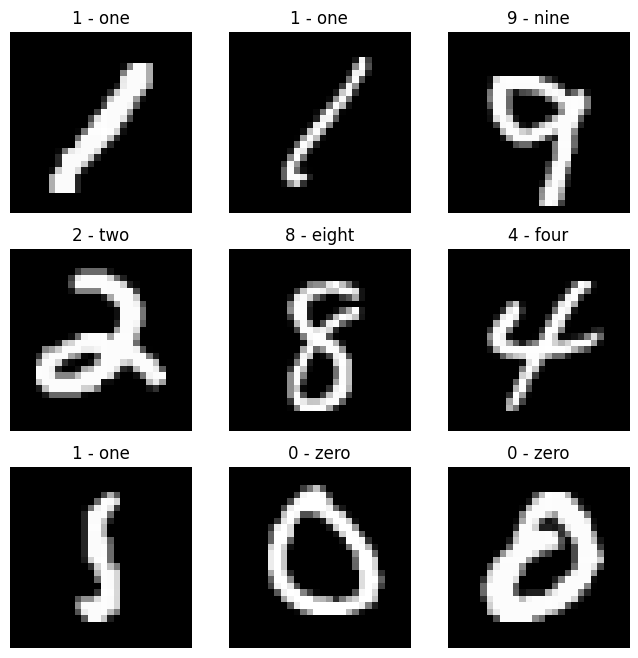

In [ ]:
labels_map = dict(zip(range(len(train_set.classes)), train_set.classes))
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

## Создание dataloader

Данные при обучении модели редко передаются по одному образцу или все разом, обычно образцы объединяются в пакеты (batches) и уже они передаются на вход модели.

Размер пакета (batch size) выбирается как $2^n$ (16, 32, 64, 128) .

Загрузчики данных будут использоваться при обучении и тестировании модели. Чтобы между эпохами модель на обучалась на одинаковых пакетах их перемешивают (shuffle).

In [ ]:
from torch.utils.data import DataLoader

In [ ]:
train_loader = DataLoader(train_set, 32, shuffle=True)

#
# По аналогии создайте test_loader
#
#

test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

## Создание модели
В этой работе будеут использованы контейнеры pytorch для построения нейронной сети, например `nn.Sequential` или `nn.Module`.

В этой работе, используя функции из модуля `torch.nn.functional` `linear` и `relu`, необходимо собрать цепочку вычислений для получения выходных значений.
При инициализации MLP необходимо создать несколько линейных слоев и использовать функцию активации (например ReLU), которые будут использоваться при прямом проходе в модели. Перед входным слоем необходимо использовать для изображений `.flatten()'.

- Линейный слой `nn.Linear`.
- Функция активации `nn.ReLU`

In [ ]:
import torch.nn as nn

In [ ]:
class MLP(nn.Module):  # nn.Module - базовый класс для всех модулей нейронной сети
    def __init__(self):
        super().__init__()
        #
        # Для первого линейного слоя количество входных параметров,
        # должно быть равно количеству значений в изображении.
        # В последнем слое, количество выводов должно быть равно количеству классов
        # в задаче классификации.
        # В промежуточных слоях количество параметров на входе должно совпадать
        # с количеством на выходе у предыдущего слоя.
        # Пример
        # self.fc1 = nn.Linear(1 * 28 * 28, 120)
        # self.fc2 = nn.Linear(__, ___)
        # self.fc3 = nn.Linear(__, 10)
        # Ваш код
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        #
        # Уплощаем данные на входе, передаем их в линейную функцию,
        # после в функцию активации. После последнего линейного слоя,
        # функция активации не требуется.
        #  Пример
        # x = x.flatten(start_dim=1) изменяет форму тензора так, чтобы он имел размерность (batch_size, 28 * 28)
        # x = F.relu(self.fc1(x))
        # x = F.relu(self.fc2(x))
        # x = self.fc3(x)
        # Ваш код
        #
        x = x.flatten(start_dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [ ]:
model = MLP() # Создайте экземпляр вашего класса

In [ ]:
print(model)

MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [ ]:
for param in model.parameters(): # вывод параметров модели
  print(param.shape)


torch.Size([128, 784])
torch.Size([128])
torch.Size([64, 128])
torch.Size([64])
torch.Size([10, 64])
torch.Size([10])


In [ ]:
for param_tensor in model.state_dict():
    print(param_tensor, "\t", model.state_dict()[param_tensor].size())

fc1.weight 	 torch.Size([128, 784])
fc1.bias 	 torch.Size([128])
fc2.weight 	 torch.Size([64, 128])
fc2.bias 	 torch.Size([64])
fc3.weight 	 torch.Size([10, 64])
fc3.bias 	 torch.Size([10])


**Сколько параметров в вашей модели?**

Ваш ответ:

fc1:

Веса:
784
×
128
=
100352

Смещения:
128

Итого: 100480

fc2:

Веса:
128
×
64
=
8192

Смещения:
64

Итого: 8256

fc3:

Веса:
64
×
10
=
640

Смещения:
10

Итого: 650

Общий результат:
100480
+
8256
+
650
=
109386


В модели 109386 параметров.

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print("Общее количество параметров:", total_params)

Общее количество параметров: 109386


## Функция потерь и оптимизатор

В задаче классификации чаще всего используется функция потерь на основе перекрестной энтропии.

В качестве оптимизатора для параметров модели можно выбрать стохастический градиентный спуск или Adam.

In [ ]:
loss_fn = nn.CrossEntropyLoss()

In [ ]:
from torch.optim import SGD

LR = 0.01 # выберите значение в диапазоне от 0.1 до 0.0001

optimizer = SGD(model.parameters(), lr=LR)

## Цикл обучения

In [ ]:
import torch.nn.functional as F

n_epochs = 10 # Укажите количество эпох от 3 до 20

best_acc = 0

for epoch in range(n_epochs):
    train_loss = 0
    train_correct = 0
    test_loss = 0
    test_correct = 0
    print(f"Эпоха №{epoch+1}")
    model.train() # переключение модели в режим обучения
    for imgs, labels in train_loader:
        #
        # Классический цикл обучения
        # 1. Обнуление градиентов с помощью метода zero_grad у оптимизатора
        # 2. Получение вывода модели по пакету данных
        # 3. Вычисление потерь на основе вывода модели и исходных значений
        # 4. Вычисление градиентов для параметров
        # 5. Обновление параметров с помощью шага ".step()" у оптимизатора
        # 6. Вычисление метрики
        optimizer.zero_grad() # 1. Обнуление градиентов с помощью метода zero_grad у оптимизатора
        outputs = model(imgs)  # 2. Получение вывода модели по пакету данных
        # outputs = model(imgs.flatten(start_dim=1))
        loss = loss_fn(outputs, labels)  # 3. Вычисление потерь на основе вывода модели и исходных значений
        loss.backward()  # 4. Вычисление градиентов для параметров
        optimizer.step()  # 5. Обновление параметров с помощью шага ".step()" у оптимизатора
        # 6. Вычисление метрики

        train_loss += loss.item() # прибавьте потери с этой итерации
        # метод .item() - возвращает значение этого тензора
        # в виде стандартного числа Python.

        train_correct += torch.sum(torch.argmax(outputs, dim=1) == labels).item() # Необходимо получить сумму совпавших значений между исходными индексами классов (labels)
        # и индексами максимальных значений в пакетах данных.
        # Вам пригодятся torch.sum, torch.argmax и .item()

    avg_train_loss = train_loss / len(train_loader) # полученную сумму потерь необходимо разделить на количество пакетов данных len(train_loader)
    train_acc = train_correct / len(train_set) # полученное количество правильно классифицированных изображений
    # необходимо разделить на количество изображений в обучающей выборке
    print(f"Потери на обучающей выборке {avg_train_loss:.5f}")
    print(f"Точность на обучающей выборке: {train_acc*100:.2f}%")

    model.eval() # переключение модели в режим оценивания
    for imgs, labels in test_loader:
        with torch.no_grad(): # работа в контексте отключенного вычисления градиентов
            # Для оценки модели:
            # 1. Получение вывода модели по пакету данных
            # 2. Вычисление потерь на основе вывода модели и исходных значений
            # 3. Вычисление метрики
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            test_loss += loss.item() # Ваш код
            test_correct += torch.sum(torch.argmax(outputs, dim=1) == labels).item() # Ваш код

    avg_test_loss = test_loss / len(test_loader) # Ваш код
    test_acc = test_correct / len(test_set) # Ваш код
    print(f"Потери на тестовой выборке {avg_test_loss:.5f}")
    print(f"Точность на тестовой выборке: {test_acc*100:.2f}%")

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
        }, "best_model_params.pth")

Эпоха №1
Потери на обучающей выборке 1.19809
Точность на обучающей выборке: 65.53%
Потери на тестовой выборке 0.45000
Точность на тестовой выборке: 86.99%
Эпоха №2
Потери на обучающей выборке 0.39186
Точность на обучающей выборке: 88.82%
Потери на тестовой выборке 0.33111
Точность на тестовой выборке: 90.40%
Эпоха №3
Потери на обучающей выборке 0.32063
Точность на обучающей выборке: 90.78%
Потери на тестовой выборке 0.28886
Точность на тестовой выборке: 91.73%
Эпоха №4
Потери на обучающей выборке 0.27851
Точность на обучающей выборке: 91.94%
Потери на тестовой выборке 0.25366
Точность на тестовой выборке: 92.90%
Эпоха №5
Потери на обучающей выборке 0.24399
Точность на обучающей выборке: 93.09%
Потери на тестовой выборке 0.22894
Точность на тестовой выборке: 93.50%
Эпоха №6
Потери на обучающей выборке 0.21592
Точность на обучающей выборке: 93.85%
Потери на тестовой выборке 0.20450
Точность на тестовой выборке: 94.29%
Эпоха №7
Потери на обучающей выборке 0.19257
Точность на обучающей выб

Для оценки модели нужно отключать вычисление градиентов `with torch.no_grad()`?**



## Загрузка модели и инференс

Проверка модели на цифрах.

Необходимо нарисовать цифру в любом графическом редакторе (Paint, Gimp, Photoshop).

Изображение должно быть черно-белое, ширина и высота 28 px, черный фон, белая цифра. Формат  png, jpg.

Для загрузки изображения в Google Colab в боковой панели откройте Files (1), и выберите вариант Upload to session storage (2).

Затем файл необходимо считать и подготовить перед тем, как передать в модель.



In [ ]:
from PIL import Image
img = Image.open('/content/Фото цифры.jpg')
print(f"Ширина и высота {img.size}, количество каналов {len(img.mode)}")
img

Ширина и высота (28, 28), количество каналов 3


In [ ]:
import torchvision.transforms as transforms
# Раскомментируйте, если цветное изображение
transform_grayscale = transforms.Grayscale()
img = transform_grayscale(img)

# Преобразования изображения
transform_to_tensor = transforms.ToTensor()
x = transform_to_tensor(img)

# Выведите размерности тензора x

#
# Ваш код
#

print(f"Размерности тензора: {x.shape}")

Размерности тензора: torch.Size([1, 28, 28])


Модель строилась с использованием пакетов данных, которые создавали экземпляры класса DataLoader, для использования одного изображения нужно создать пакет из одного изображения с использованием  метода тензора `unsqueeze` или `unsqueeze_`.

In [ ]:
#
# Ваш код
#
x = x.unsqueeze(0)  # Добавляем размерность пакета (Batch Size = 1)

print(f"Размерности тензора: {x.shape}")

Размерности тензора: torch.Size([1, 1, 28, 28])


In [ ]:
best_model = MLP() # Новый экземпляр класса модели
best_model_params = torch.load("best_model_params.pth") # Укажите путь до сохраненного файла
state_dict = best_model_params["model_state_dict"] # Из best_model_params извлеките по соответствующему ключу параметры модели
# Для best_model используйте метод load_state_dict и передайте в него словарь с параметрами.
# Переключите модель в режим проверки

# Загрузка весов в модель
best_model.load_state_dict(state_dict)

# Переключение модели в режим проверки
best_model.eval()

print("Модель загружена и готова к использованию.")

Модель загружена и готова к использованию.


<ipython-input-22-c0c8b0bb5d56>:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_model_params = torch.load("best_model_params.pth") # Укажите путь до сохраненного файла

Тестирование модели
 Передайте на вход модели подготовленный тензор. Из вывода модели получите индекс наибольшего значения (`argmax`) и по индексу получите результат из массива ярлыков классов (`test_set.classes`).

In [ ]:
#
# Ваш код
#

# Передача изображения в модель
with torch.no_grad():  # Отключаем градиенты, т.к. они не нужны для предсказания
    output = best_model(x)

# Получение индекса класса с наибольшей вероятностью
predicted_class = torch.argmax(output, dim=1).item()

print(f"Предсказанный класс: {test_set.classes[predicted_class]}")

Предсказанный класс: 2 - two


In [ ]:
print(f"Лучшая точность на тестовой выборке: {best_acc*100:.2f}%")

Лучшая точность на тестовой выборке: 95.65%


**Правильно ли предсказала модель цифру?**

Ваш ответ: Да, модель правильно предсказала цифру

**Лучшая точность на тестовой выборке для вашей модели.**

Ваш ответ: 95.65 %




## Задание 1.

1. Подбор гиперпараметров
Используя рабочий код модели и ее обучения, используйте разные варианты скорости обучения, количества параметров в скрытых слоя модели, количества эпох, размера батчей.
2. Выведите гиперпараметры лучшей  модели.


In [ ]:
# Ваш код
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from itertools import product

# Определение модели с возможностью задания количества нейронов
class MLP(nn.Module):
    def __init__(self, hidden_units):  # Добавляем hidden_units
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, hidden_units)  # Входной слой
        self.fc2 = nn.Linear(hidden_units, 10)  # Выходной слой (10 классов)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Разворачиваем тензор
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Возможные значения гиперпараметров
learning_rates = [0.001, 0.01, 0.1]
hidden_units_list = [64, 128, 256]
batch_sizes = [16, 32, 64]
n_epochs_list = [5, 10, 15]

best_acc = 0
best_params = {}

for lr, hidden_units, batch_size, n_epochs in product(learning_rates, hidden_units_list, batch_sizes, n_epochs_list):
    print(f"Обучение с lr={lr}, hidden_units={hidden_units}, batch_size={batch_size}, n_epochs={n_epochs}")

    # Определение модели с заданным количеством нейронов
    model = MLP(hidden_units=hidden_units)  # Теперь параметр корректный
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_set, batch_size=batch_size)

    # Обучение модели
    for epoch in range(n_epochs):
        model.train()
        for imgs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

    # Оценка точности модели
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            outputs = model(imgs)
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    test_acc = correct / total
    print(f"Точность: {test_acc*100:.2f}%")

    # Сохранение лучших параметров
    if test_acc > best_acc:
        best_acc = test_acc
        best_params = {
            "learning_rate": lr,
            "hidden_units": hidden_units,
            "batch_size": batch_size,
            "n_epochs": n_epochs
        }
        torch.save(model.state_dict(), "best_model.pth")

print("Лучшие гиперпараметры:")
print(best_params)
print(f"Лучшая точность: {best_acc*100:.2f}%")

Обучение с lr=0.001, hidden_units=64, batch_size=16, n_epochs=5
Точность: 97.26%
Обучение с lr=0.001, hidden_units=64, batch_size=16, n_epochs=10
Точность: 97.28%
Обучение с lr=0.001, hidden_units=64, batch_size=16, n_epochs=15
Точность: 97.22%
Обучение с lr=0.001, hidden_units=64, batch_size=32, n_epochs=5
Точность: 97.47%
Обучение с lr=0.001, hidden_units=64, batch_size=32, n_epochs=10
Точность: 97.56%
Обучение с lr=0.001, hidden_units=64, batch_size=32, n_epochs=15
Точность: 97.46%
Обучение с lr=0.001, hidden_units=64, batch_size=64, n_epochs=5
Точность: 96.72%
Обучение с lr=0.001, hidden_units=64, batch_size=64, n_epochs=10
Точность: 97.66%
Обучение с lr=0.001, hidden_units=64, batch_size=64, n_epochs=15
Точность: 97.45%
Обучение с lr=0.001, hidden_units=128, batch_size=16, n_epochs=5
Точность: 97.70%
Обучение с lr=0.001, hidden_units=128, batch_size=16, n_epochs=10
Точность: 97.15%
Обучение с lr=0.001, hidden_units=128, batch_size=16, n_epochs=15
Точность: 97.91%
Обучение с lr=0.0

## Задание 2.

1. Из встроенных датасетов torchvision загрузите тестовую и обучающую выборки из EMNIST часть (split) Balanced или Letters.
2. Постройте код модели и ее обучения, используйте разные варианты скорости обучения, количества параметров в скрытых слоя модели, количества эпох, размера батчей.
2. Выведите гиперпараметры лучшей модели.


In [1]:
# Ваш код
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import EMNIST
import torch.nn as nn
import torch.nn.functional as F
from itertools import product

# Определяем преобразования: перевод в тензор и нормализация
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Загрузка EMNIST (Balanced или Letters)
split_type = "balanced"  # Или "letters"
train_set = EMNIST(root="./data", split=split_type, train=True, download=True, transform=transform)
test_set = EMNIST(root="./data", split=split_type, train=False, download=True, transform=transform)

# Разделение на батчи
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64)

class EMNISTModel(nn.Module):
    def __init__(self, hidden_units=128):
        super(EMNISTModel, self).__init__()
        self.fc1 = nn.Linear(28 * 28, hidden_units)
        self.fc2 = nn.Linear(hidden_units, hidden_units)
        self.fc3 = nn.Linear(hidden_units, len(train_set.classes))  # Количество классов

    def forward(self, x):
        x = x.view(-1, 28 * 28)  # Разворачиваем в вектор
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

learning_rates = [0.001, 0.01, 0.1]
hidden_units_list = [64, 128, 256]
batch_sizes = [32, 64, 128]
n_epochs_list = [5, 10, 15]

best_acc = 0
best_params = {}

for lr, hidden_units, batch_size, n_epochs in product(learning_rates, hidden_units_list, batch_sizes, n_epochs_list):
    print(f"Обучение: lr={lr}, hidden_units={hidden_units}, batch_size={batch_size}, n_epochs={n_epochs}")

    # Создаем загрузчики данных с текущим batch_size
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_set, batch_size=batch_size)

    # Создаем модель, функцию потерь и оптимизатор
    model = EMNISTModel(hidden_units=hidden_units)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    # Обучение модели
    for epoch in range(n_epochs):
        model.train()
        for imgs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

    # Оценка точности на тестовой выборке
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            outputs = model(imgs)
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    test_acc = correct / total
    print(f"Точность: {test_acc*100:.2f}%")

    # Сохранение лучших параметров
    if test_acc > best_acc:
        best_acc = test_acc
        best_params = {
            "learning_rate": lr,
            "hidden_units": hidden_units,
            "batch_size": batch_size,
            "n_epochs": n_epochs
        }
        torch.save(model.state_dict(), "best_emnist_model.pth")

print("Лучшие гиперпараметры:", best_params)
print(f"Лучшая точность: {best_acc*100:.2f}%")

100%|██████████| 562M/562M [01:14<00:00, 7.53MB/s]


Extracting ./data/EMNIST/raw/gzip.zip to ./data/EMNIST/raw
Обучение: lr=0.001, hidden_units=64, batch_size=32, n_epochs=5
Точность: 78.64%
Обучение: lr=0.001, hidden_units=64, batch_size=32, n_epochs=10
Точность: 79.60%
Обучение: lr=0.001, hidden_units=64, batch_size=32, n_epochs=15
Точность: 79.61%
Обучение: lr=0.001, hidden_units=64, batch_size=64, n_epochs=5
Точность: 78.13%
Обучение: lr=0.001, hidden_units=64, batch_size=64, n_epochs=10
Точность: 78.63%
Обучение: lr=0.001, hidden_units=64, batch_size=64, n_epochs=15
Точность: 79.81%
Обучение: lr=0.001, hidden_units=64, batch_size=128, n_epochs=5
Точность: 78.00%
Обучение: lr=0.001, hidden_units=64, batch_size=128, n_epochs=10
Точность: 79.54%
Обучение: lr=0.001, hidden_units=64, batch_size=128, n_epochs=15
Точность: 80.73%
Обучение: lr=0.001, hidden_units=128, batch_size=32, n_epochs=5
Точность: 80.88%
Обучение: lr=0.001, hidden_units=128, batch_size=32, n_epochs=10
Точность: 81.28%
Обучение: lr=0.001, hidden_units=128, batch_size=

KeyboardInterrupt: 

In [2]:
print("Лучшие гиперпараметры:", best_params)
print(f"Лучшая точность: {best_acc*100:.2f}%")

Лучшие гиперпараметры: {'learning_rate': 0.001, 'hidden_units': 256, 'batch_size': 128, 'n_epochs': 15}
Лучшая точность: 83.77%
